In [3]:
import tensorflow as tf
import tensorflow_datasets as tfds
import tensorflow.keras as keras
import os
os.environ["PATH"] += os.pathsep + r"C:\Program Files\Graphviz\bin"

In [4]:
from tensorflow.random import shuffle

In [5]:
ds, ds_info = tfds.load(
    "tf_flowers",  # Nombre del dataset
    with_info=True,  # Cargar los nombres de las categorias
    shuffle_files=True,  # Mezclar los datos
    split=[
        "train[:80%]",  # del 0 al 80% set de entrenamiento
        "train[80%:90%]",  # del 80% al 90% (10%) set de validacion
        "train[90%:]",  # del 90% al 100% (10%) prueba
    ],  # set de entrenamiento, validacion y prueba
    as_supervised=True,  # Devuelve (imagen, etiqueta) en vez de un diccionario
    read_config=tfds.ReadConfig(
        shuffle_seed=23
    ),  # La semilla de aleatoriedad debe ser la misma
)
# Extraer los datasets
train, val, test = ds[0], ds[1], ds[2]

print(
    f"Tamaño set de entrenamiento {len(train)}\n"
    f"Tamaño set de validacion {len(val)}\n"
    f"Tamaño set de prueba {len(test)}"
)

Tamaño set de entrenamiento 2936
Tamaño set de validacion 367
Tamaño set de prueba 367


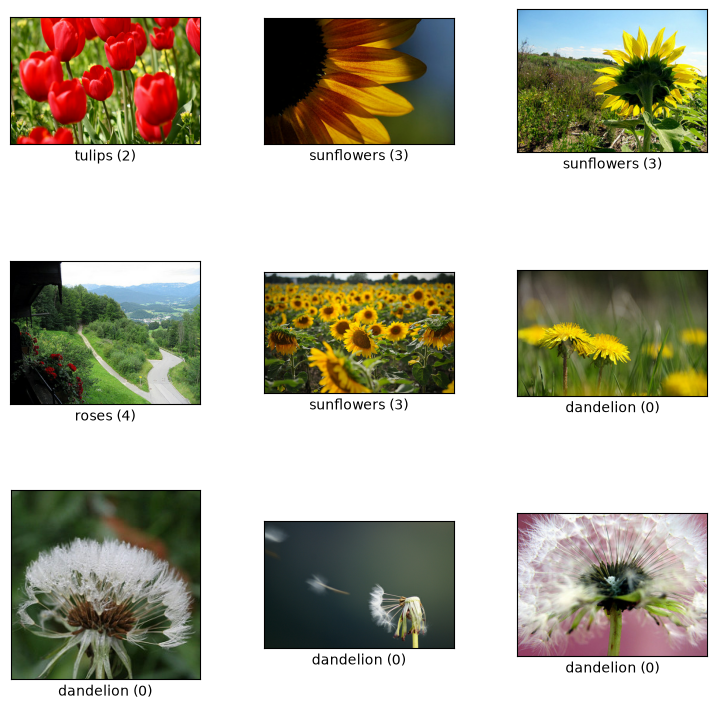

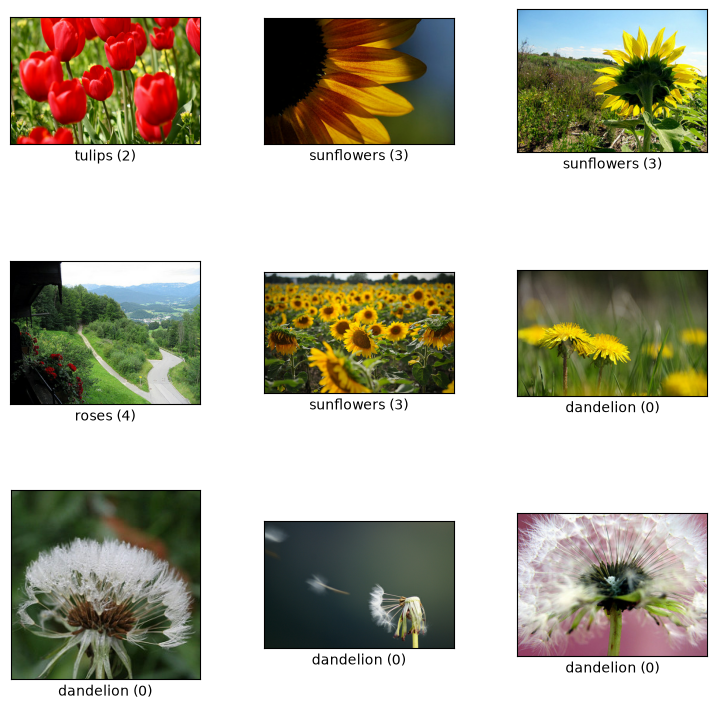

In [6]:
# Mostrar imagenes, show_examples es un metodo de tensor_flow
tfds.show_examples(train, ds_info)

In [7]:
# Extraccion de imagenes para revisar caracteristicas
for img, lbl in train.take(1):
    print(
        f"Mínimo: {img.numpy().min()}, Máximo: {img.numpy().max()}\n"
        f"Tipo de dato: {img.dtype}\n"
        f"Tamaño {img.get_shape()}")
    

Mínimo: 0, Máximo: 255
Tipo de dato: <dtype: 'uint8'>
Tamaño (333, 500, 3)


Modelo: Xception

Tamaño minimo de la entrada: 71x71x3

Tipo de dato de entrada: float32 y valores entre -1 y 1


In [8]:
def convertidor(img , lbl):
    #Ajustando las medidas a 71x71
    img = tf.image.resize(img, (71,71))
    #Convirtiendo de 0 a 255 a -1 y 1 (0/127.5)-1 = -1 y (255/127.5)-1=1
    #Con dtype se convierte al formato float32
    img = tf.image.convert_image_dtype((img/127.5)-1 , dtype=tf.float32)
    return img , lbl

In [9]:
#Bucle para ajustar formato de 1 imagen

for img, lbl in train.map(convertidor).take(1):
    print(f"Mínimo {img.numpy().min():.2f}, Máximo {img.numpy().max():.2f}\n"
        f"Formato de image: {img.dtype}\n"
        f"Tamaño: {img.get_shape()}") #Devuelve las medidas en formato de tensor

Mínimo -1.00, Máximo 1.00
Formato de image: <dtype: 'float32'>
Tamaño: (71, 71, 3)


Importar agente y congelar factores de entrenamiento

In [10]:
tf.random.set_seed(123) #Se congela el grupo seleccionado de manera aleatoria

xception = keras.applications.Xception(
    weights = "imagenet",
    input_shape = (71,71,3),
    include_top = False # (False) No incluir capa de salida 
)
xception.summary()


Model: "xception"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 71, 71, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 35, 35,    │        864 │ input_layer[0][0] │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_bn     │ (None, 35, 35,    │        128 │ block1_conv1[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_act    │ (None, 35, 35,    │          0 │ block1_conv1_bn[… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 33, 33,    │     18,432 │ block1_conv1_act… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_bn     │ (None, 33, 33,    │        256 │ block1_conv2[0][… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_act    │ (None, 33, 33,    │          0 │ block1_conv2_bn[… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1     │ (None, 33, 33,    │      8,768 │ block1_conv2_act… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1_bn  │ (None, 33, 33,    │        512 │ block2_sepconv1[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_act │ (None, 33, 33,    │          0 │ block2_sepconv1_… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2     │ (None, 33, 33,    │     17,536 │ block2_sepconv2_… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_bn  │ (None, 33, 33,    │        512 │ block2_sepconv2[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 17, 17,    │      8,192 │ block1_conv2_act… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 17, 17,    │          0 │ block2_sepconv2_… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 17, 17,    │        512 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 17, 17,    │          0 │ block2_pool[0][0… │
│                     │ 128)              │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_sepconv1_act │ (None, 17, 17,    │          0 │ add[0][0]       

 Total params: 20,861,480 (79.58 MB)

 Trainable params: 20,806,952 (79.37 MB)

 Non-trainable params: 54,528 (213.00 KB)

In [11]:
#Congelar los parametros entrenables
xception.trainable=False
xception.summary()

Model: "xception"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 71, 71, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 35, 35,    │        864 │ input_layer[0][0] │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_bn     │ (None, 35, 35,    │        128 │ block1_conv1[0][… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_act    │ (None, 35, 35,    │          0 │ block1_conv1_bn[… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 33, 33,    │     18,432 │ block1_conv1_act… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_bn     │ (None, 33, 33,    │        256 │ block1_conv2[0][… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_act    │ (None, 33, 33,    │          0 │ block1_conv2_bn[… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1     │ (None, 33, 33,    │      8,768 │ block1_conv2_act… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1_bn  │ (None, 33, 33,    │        512 │ block2_sepconv1[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_act │ (None, 33, 33,    │          0 │ block2_sepconv1_… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2     │ (None, 33, 33,    │     17,536 │ block2_sepconv2_… │
│ (SeparableConv2D)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_bn  │ (None, 33, 33,    │        512 │ block2_sepconv2[… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 17, 17,    │      8,192 │ block1_conv2_act… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 17, 17,    │          0 │ block2_sepconv2_… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 17, 17,    │        512 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 17, 17,    │          0 │ block2_pool[0][0… │
│                     │ 128)              │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_sepconv1_act │ (None, 17, 17,    │          0 │ add[0][0]       

 Total params: 20,861,480 (79.58 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 20,861,480 (79.58 MB)

Estuctura del modelo

MODELO = CAPA DE ENTRADA -XCEPTION (CONGELADO) --CAPA DE SALIDA

Model: "modelo"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Entrada (InputLayer)            │ (None, 71, 71, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 3, 3, 2048)     │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Aplanar (Flatten)               │ (None, 18432)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_1 (Dense)                 │ (None, 128)            │     2,359,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Salida (Dense)                  │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,221,549 (88.58 MB)

 Trainable params: 2,360,069 (9.00 MB)

 Non-trainable params: 20,861,480 (79.58 MB)

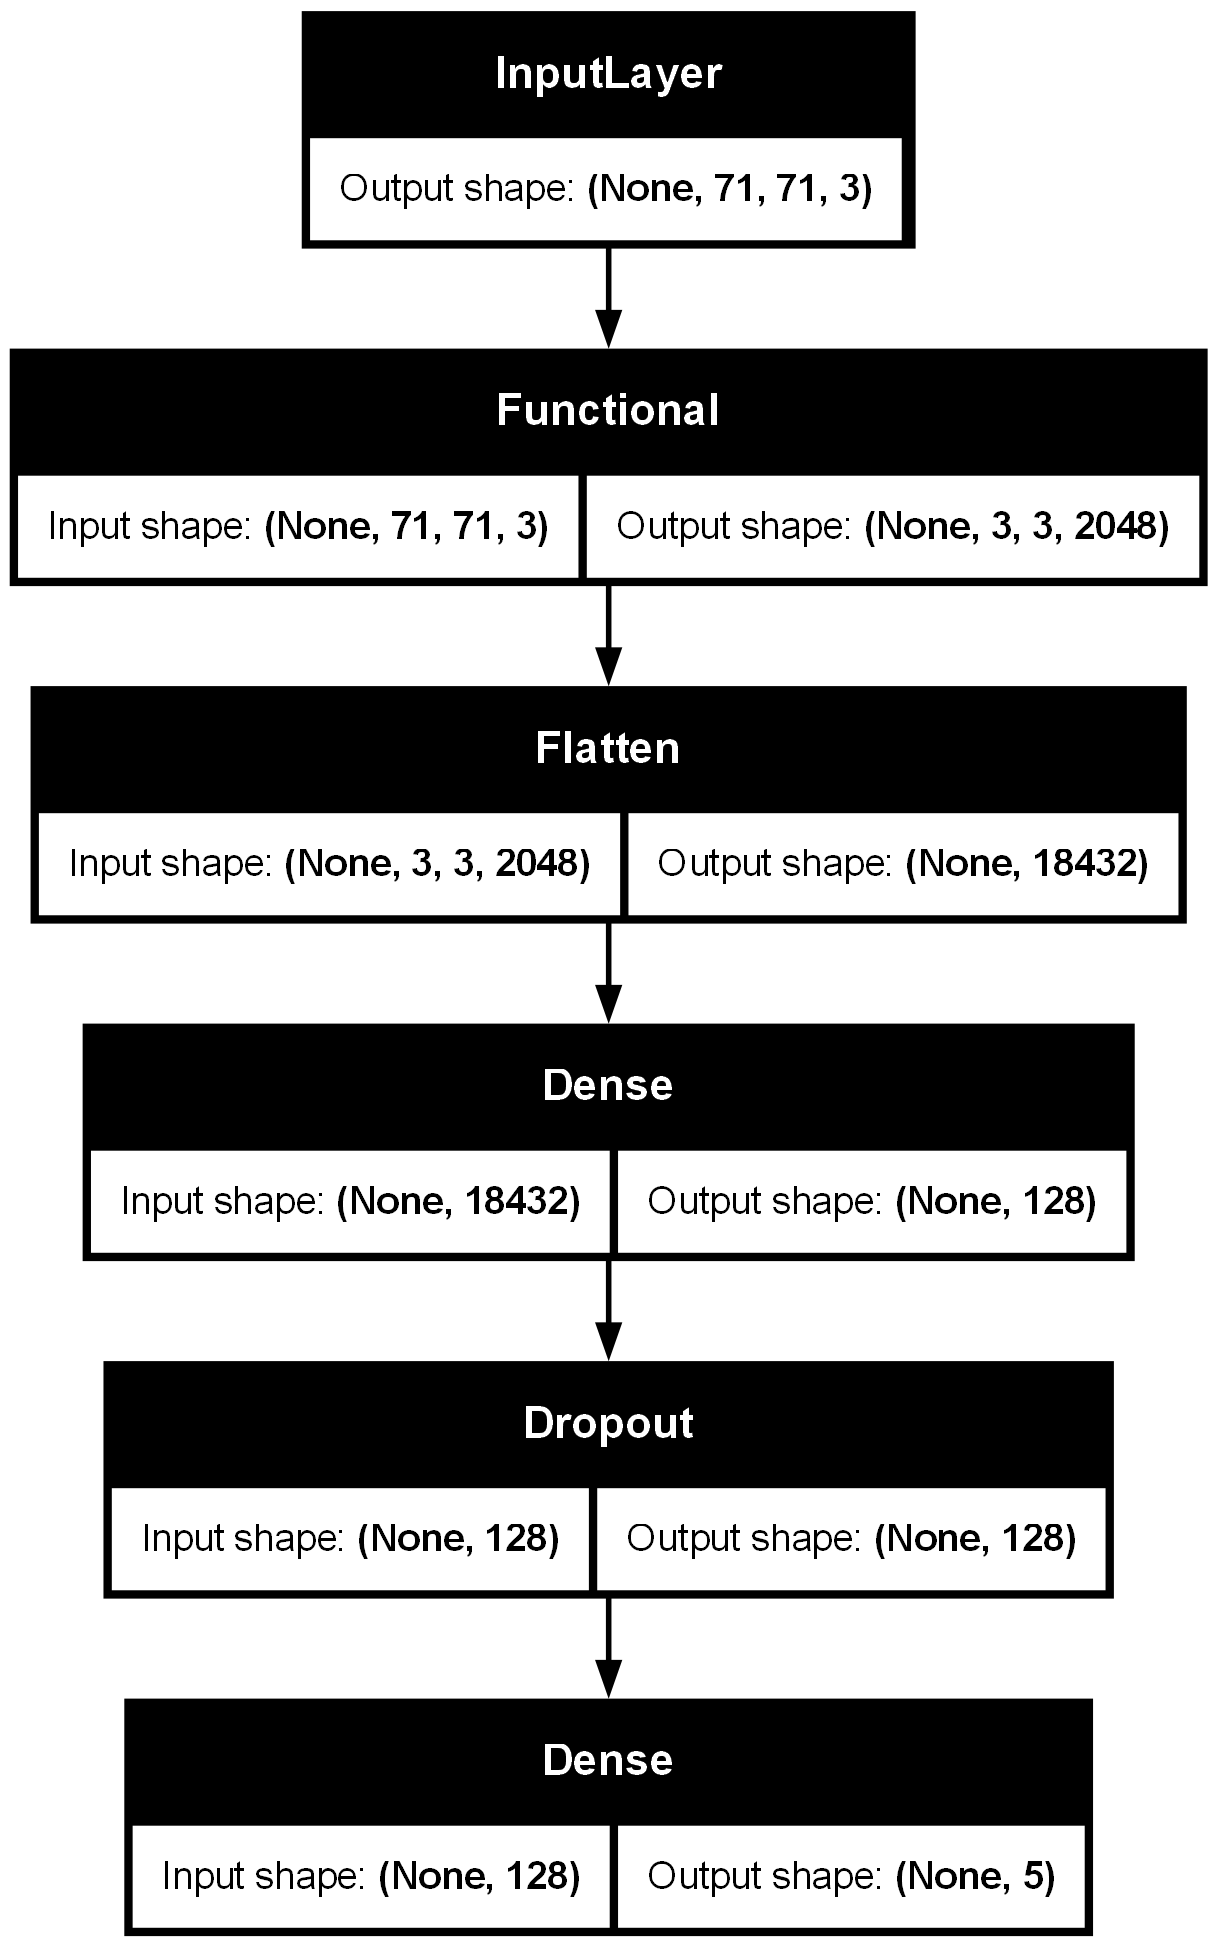

In [12]:
# Numero de categorias
NUM_CLASES = ds_info.features["label"].num_classes
# Capa de entrada
entrada = keras.Input(shape=(71,71,3), name="Entrada")
# Conectar entrada al modelo pre-entrenado
x = xception(entrada)

#CREAR SALIDA Y CONECTAR A LA ENTRADA
# 1. Capa de aplanamiento
x = keras.layers.Flatten(name="Aplanar")(x)
# 2. Capa "Dense" con 128 neuronas "relu" pone 0 a los numeros negativos
x = keras.layers.Dense(128, activation= "relu", name="Dense_1")(x)
# 3. Capa "Dropout" durante el entrenamiento apaga al azar el 50% de las neuronas 
# al predecir no apaga nada 
x = keras.layers.Dropout(0.5, name= "Dropout_1")(x)
# 4. Capa "Dense" con 10 neuronas de salida, con softmax covierte los resultados en
# probabilidades que suman 1
salida = keras.layers.Dense(NUM_CLASES, activation= "softmax", name="Salida")(x)
# Y conectar "entrada" y "salida" para crear el modelo
modelo = keras.Model(entrada, salida, name="modelo")
# Caracteristicas del modelo
modelo.summary()
# Dibujar los bloques que hacen el modelo
keras.utils.plot_model(modelo, show_shapes=True)

In [13]:
# Es el numero de imagenes para entrenar
BATCH_SIZE = 32
# Crear lotes de entrenamiento
train_batch = train.map(convertidor).batch(BATCH_SIZE)
val_batch = val.map(convertidor).batch(BATCH_SIZE)
test_batch = test.map(convertidor).batch(BATCH_SIZE)

In [14]:
# Compilar el modelo
modelo.compile(
    optimizer = keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics= ["sparse_categorical_accuracy"]
)
# Detener el entrenamiento si la validación deja de mejorar
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1,
)

# Entrenar por iteraciones
epochs = 20
modelo.fit(
    train_batch,
    epochs=epochs,
    validation_data=val_batch,
    callbacks=[early_stop],
)

Epoch 1/20


c:\Users\kevin\.antigravity-ide\MachineLearning\venv311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


92/92 ━━━━━━━━━━━━━━━━━━━━ 23s 226ms/step - loss: 1.4925 - sparse_categorical_accuracy: 0.4591 - val_loss: 0.9444 - val_sparse_categorical_accuracy: 0.6267
Epoch 2/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 237ms/step - loss: 1.0302 - sparse_categorical_accuracy: 0.5739 - val_loss: 0.7704 - val_sparse_categorical_accuracy: 0.7084
Epoch 3/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 237ms/step - loss: 0.9638 - sparse_categorical_accuracy: 0.6056 - val_loss: 0.7465 - val_sparse_categorical_accuracy: 0.7166
Epoch 4/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 23s 244ms/step - loss: 0.9074 - sparse_categorical_accuracy: 0.6458 - val_loss: 0.7320 - val_sparse_categorical_accuracy: 0.7357
Epoch 5/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 243ms/step - loss: 0.8271 - sparse_categorical_accuracy: 0.6584 - val_loss: 0.7469 - val_sparse_categorical_accuracy: 0.7330
Epoch 6/20
92/92 ━━━━━━━━━━━━━━━━━━━━ 22s 240ms/step - loss: 0.7886 - sparse_categorical_accuracy: 0.6744 - val_loss: 0.6977 - val_sparse_categorical_accuracy: 0.7520
Epoch 7/2

In [15]:
perdida, precision = modelo.evaluate(test_batch)
print(f"Precisión en prueba: {precision:.2%}")

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 170ms/step - loss: 0.7069 - sparse_categorical_accuracy: 0.7411
Precisión en prueba: 74.11%


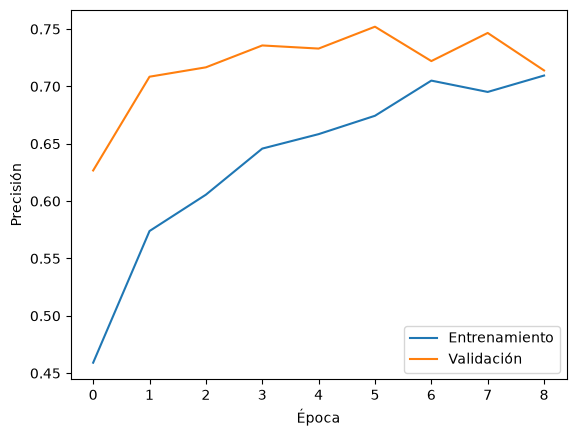

In [18]:
import matplotlib.pyplot as plt

h = modelo.history.history
plt.plot(h["sparse_categorical_accuracy"], label="Entrenamiento")
plt.plot(h["val_sparse_categorical_accuracy"], label="Validación")
plt.xlabel("Época"); plt.ylabel("Precisión"); plt.legend(); plt.show()

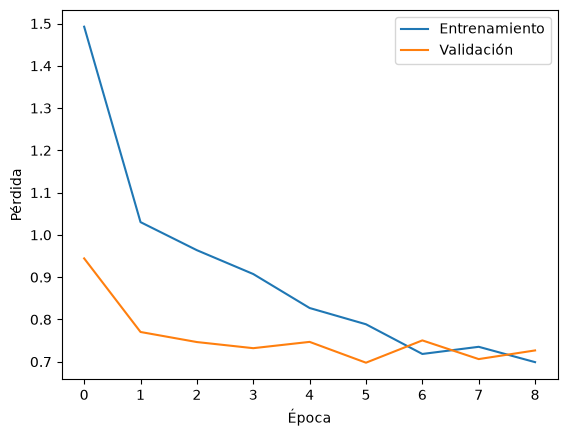

In [19]:
plt.plot(h["loss"], label="Entrenamiento")
plt.plot(h["val_loss"], label="Validación")
plt.xlabel("Época"); plt.ylabel("Pérdida"); plt.legend(); plt.show()